In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [56]:
# %pip install matplotlib seaborn

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Matplotlib version:", plt.matplotlib.__version__)
print("Seaborn version:", sns.__version__)
print("Visualization libraries are working!")

Matplotlib version: 3.11.2
Seaborn version: 0.13.2
Visualization libraries are working!


In [58]:
df = pd.read_csv(
    r"C:\Users\Aniket Sharma\Documents\SWYNEX_Data_Prepration\output\cleaned_data.csv"
)

In [59]:
print("Data loaded successfully!")

print(df)

Data loaded successfully!
              hotel  is_canceled  lead_time  arrival_date_year  \
0      Resort Hotel            0        342               2015   
1      Resort Hotel            0        737               2015   
2      Resort Hotel            0          7               2015   
3      Resort Hotel            0         13               2015   
4      Resort Hotel            0         14               2015   
...             ...          ...        ...                ...   
87391    City Hotel            0         23               2017   
87392    City Hotel            0        102               2017   
87393    City Hotel            0         34               2017   
87394    City Hotel            0        109               2017   
87395    City Hotel            0        205               2017   

      arrival_date_month  arrival_date_week_number  arrival_date_day_of_month  \
0                   July                        27                          1   
1                  

In [60]:
print(df.head())

          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   
3  Resort Hotel            0         13               2015               July   
4  Resort Hotel            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  agent  company  \
0                        0                     0       2  ...    NaN      NaN   
1 

In [61]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 87396
Columns: 33


In [62]:
total_bookings = len(df)

cancelled_bookings = df["is_canceled"].sum()

cancellation_rate = (cancelled_bookings / total_bookings) * 100

print("Total bookings:", total_bookings)
print("Cancelled bookings:", cancelled_bookings)
print("Cancellation rate:", round(cancellation_rate, 2), "%")

Total bookings: 87396
Cancelled bookings: 24025
Cancellation rate: 27.49 %


In [63]:
booking_status = df["is_canceled"].value_counts() 
print(booking_status)

is_canceled
0    63371
1    24025
Name: count, dtype: int64


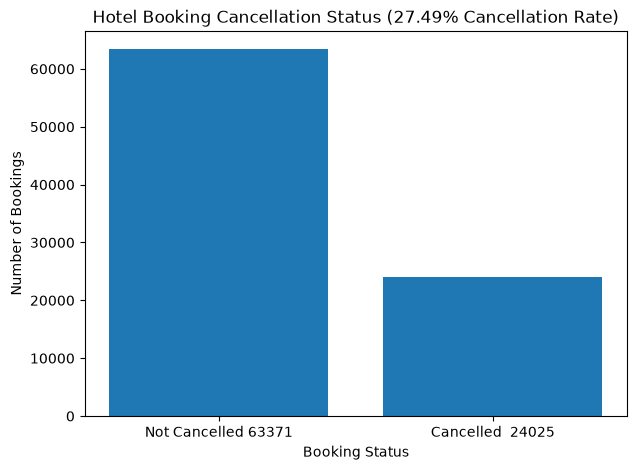

In [64]:
status_labels = ["Not Cancelled 63371", "Cancelled  24025"]
status_counts = [
    booking_status.get(0, 0),
    booking_status.get(1, 0)
]

plt.figure(figsize=(7, 5))

plt.bar(status_labels, status_counts)

plt.title("Hotel Booking Cancellation Status (27.49% Cancellation Rate)")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")

plt.show()

1. Overall Cancellation Rate
The dataset has an overall cancellation rate of **27.49%**, meaning more than one-quarter of recorded bookings were cancelled.

In [65]:
hotel_bookings = df["hotel"].value_counts()

print(hotel_bookings)

hotel
City Hotel      53428
Resort Hotel    33968
Name: count, dtype: int64


In [66]:
hotel_cancellation = (
    df.groupby("hotel")["is_canceled"]
      .mean()
      .mul(100)
      .round(2)
)

print(hotel_cancellation)

hotel
City Hotel      30.04
Resort Hotel    23.48
Name: is_canceled, dtype: float64


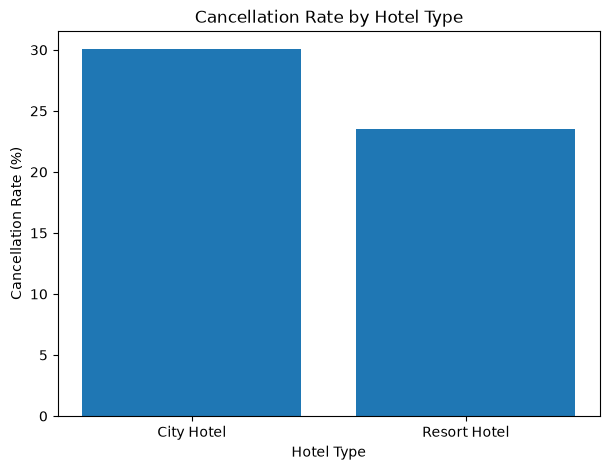

In [67]:
plt.figure(figsize=(7, 5))

plt.bar(
    hotel_cancellation.index,
    hotel_cancellation.values
)

plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")

plt.show()

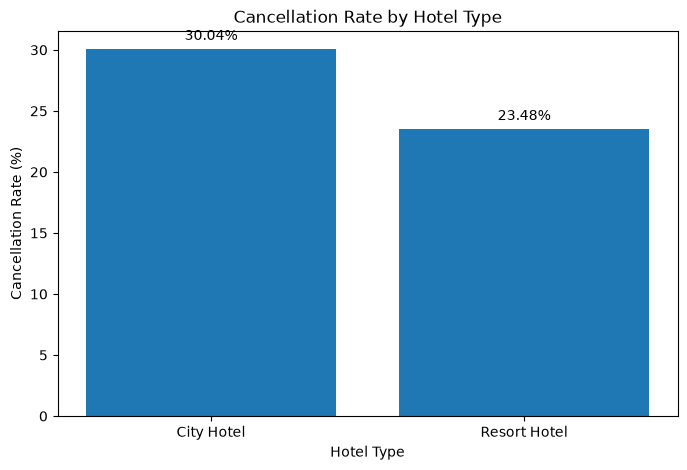

In [68]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    hotel_cancellation.index,
    hotel_cancellation.values
)

plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")

# Add cancellation percentage on top of each bar
for bar, value in zip(bars, hotel_cancellation.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.show()

2-Cancellation Rate by Hotel Type
City Hotel bookings had a cancellation rate of **30.04%**, compared with **23.48%** for Resort Hotel bookings. This represents a difference of **6.56 percentage points**.



In [69]:
df["lead_time"].describe()

count    87396.000000
mean        79.891368
std         86.052325
min          0.000000
25%         11.000000
50%         49.000000
75%        125.000000
max        737.000000
Name: lead_time, dtype: float64

In [70]:
df["lead_time_group"] = pd.cut(
    df["lead_time"],
    bins=[-1, 7, 30, 90, 180, float("inf")],
    labels=[
        "0–7 days",
        "8–30 days",
        "31–90 days",
        "91–180 days",
        "181+ days"
    ]
)

print(df["lead_time_group"].value_counts().sort_index())

lead_time_group
0–7 days       18304
8–30 days      16340
31–90 days     22744
91–180 days    18243
181+ days      11765
Name: count, dtype: int64


In [71]:
lead_time_cancellation = (
    df.groupby("lead_time_group", observed=True)["is_canceled"]
      .mean()
      .mul(100)
      .round(2)
)

print(lead_time_cancellation)

lead_time_group
0–7 days        8.43
8–30 days      25.37
31–90 days     32.01
91–180 days    34.98
181+ days      39.74
Name: is_canceled, dtype: float64


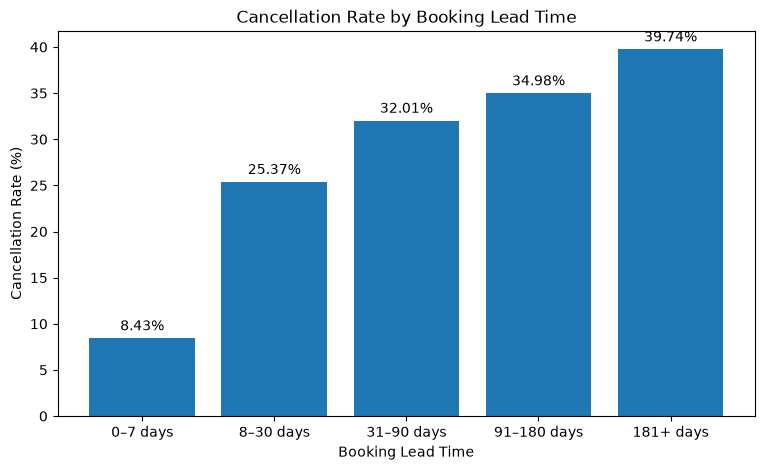

In [72]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    lead_time_cancellation.index,
    lead_time_cancellation.values
)

plt.title("Cancellation Rate by Booking Lead Time")
plt.xlabel("Booking Lead Time")
plt.ylabel("Cancellation Rate (%)")

# Add percentage labels on bars
for bar, value in zip(bars, lead_time_cancellation.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.show()

In [73]:
print(lead_time_cancellation)


lead_time_group
0–7 days        8.43
8–30 days      25.37
31–90 days     32.01
91–180 days    34.98
181+ days      39.74
Name: is_canceled, dtype: float64


Bookings made further in advance showed higher cancellation rates in this dataset. Cancellation increased from 8.43% for bookings made 0–7 days before arrival to 39.74% for bookings made 181+ days before arrival.

In [74]:
df["deposit_type"].value_counts()

deposit_type
No Deposit    86251
Non Refund     1038
Refundable      107
Name: count, dtype: int64

In [75]:
deposit_counts = df["deposit_type"].value_counts()

print(deposit_counts)

deposit_type
No Deposit    86251
Non Refund     1038
Refundable      107
Name: count, dtype: int64


In [76]:
deposit_cancellation = (
    df.groupby("deposit_type")["is_canceled"]
      .mean()
      .mul(100)
      .round(2)
)

print(deposit_cancellation)

deposit_type
No Deposit    26.68
Non Refund    94.70
Refundable    24.30
Name: is_canceled, dtype: float64


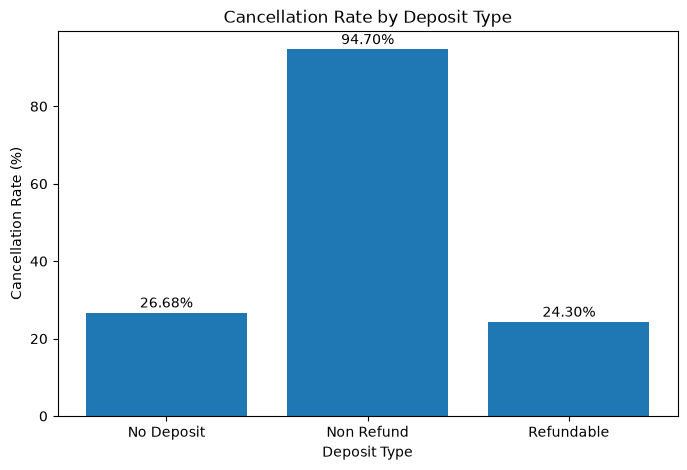

In [77]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    deposit_cancellation.index,
    deposit_cancellation.values
)

plt.title("Cancellation Rate by Deposit Type")
plt.xlabel("Deposit Type")
plt.ylabel("Cancellation Rate (%)")

# Add percentage labels
for bar, value in zip(bars, deposit_cancellation.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.show()

4. Deposit Type and Cancellation
Cancellation rates varied substantially by deposit type. **Non Refund** bookings had a **94.70%** cancellation rate, compared with **26.68%** for No Deposit bookings and **24.30%** for Refundable bookings.



In [78]:
market_segment_counts = df["market_segment"].value_counts()

print(market_segment_counts)

market_segment
Online TA        51618
Offline TA/TO    13889
Direct           11804
Groups            4942
Corporate         4212
Complementary      702
Aviation           227
Undefined            2
Name: count, dtype: int64


In [79]:
market_cancellation = (
    df.groupby("market_segment")["is_canceled"]
      .mean()
      .mul(100)
      .round(2)
)

print(market_cancellation)

market_segment
Aviation          19.82
Complementary     12.54
Corporate         12.11
Direct            14.72
Groups            27.01
Offline TA/TO     14.85
Online TA         35.35
Undefined        100.00
Name: is_canceled, dtype: float64


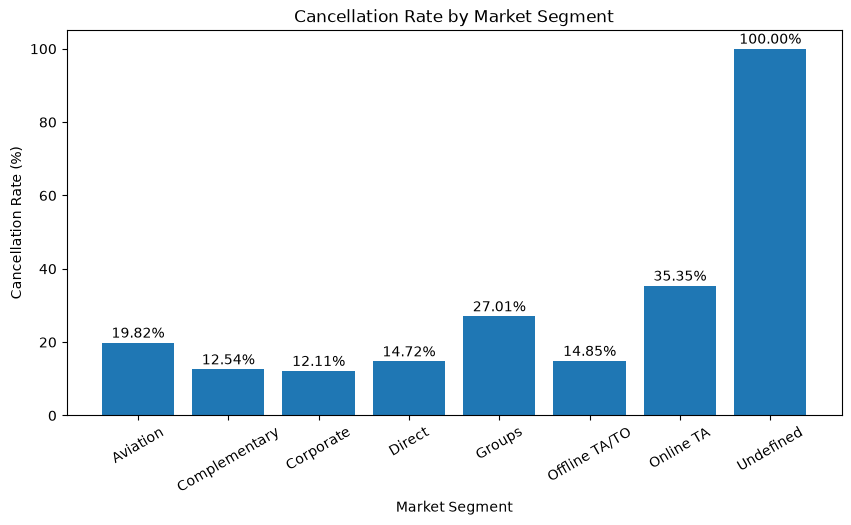

In [80]:
plt.figure(figsize=(10, 5))

bars = plt.bar(
    market_cancellation.index,
    market_cancellation.values
)

plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate (%)")

# Add percentage labels
for bar, value in zip(bars, market_cancellation.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=30)
plt.show()

5. Market Segment and Cancellation
Cancellation rates varied across market segments. **Online TA** bookings had a **35.35%** cancellation rate, while **Corporate** bookings had **12.11%**. The Undefined segment showed a 100% cancellation rate, but this result should be interpreted carefully based on its booking volume.



In [81]:
print(market_cancellation)

market_segment
Aviation          19.82
Complementary     12.54
Corporate         12.11
Direct            14.72
Groups            27.01
Offline TA/TO     14.85
Online TA         35.35
Undefined        100.00
Name: is_canceled, dtype: float64


In [82]:
customer_type_counts = df["customer_type"].value_counts()

print(customer_type_counts)

customer_type
Transient          71986
Transient-Party    11727
Contract            3139
Group                544
Name: count, dtype: int64


In [83]:
print(deposit_cancellation)

deposit_type
No Deposit    26.68
Non Refund    94.70
Refundable    24.30
Name: is_canceled, dtype: float64


Model and Decision Relevance

The analysis identifies several variables that may be useful candidate features for a future booking cancellation prediction model:

- Hotel type
- Lead time
- Deposit type
- Market segment

These variables show different cancellation patterns in the dataset and can therefore be investigated further during feature engineering and predictive modeling.

The EDA findings show associations and patterns in the data; they do not establish causal relationships.